# Calidad de datos: qué defecto rompe cada cifra

Flota multi-planta de Returnable Packaging Logistics (RPL) con movimientos MB51
sintéticos: 18 meses, 14 plantas, corte al 2026-06-30.

La pregunta de Fase 4: qué defecto de un extracto MB51 y de su maestro rompe cada
cifra de Fase 1 a 3, si el pipeline lo detecta por su causa y cuánto mueve cada
cifra publicada (ADR-027).

El generador inyecta 18 defectos típicos de un extracto real (ADR-028, ADR-029) y
cuatro ciegos que se midieron antes de tener regla (ADR-033); hoy cada uno tiene
una regla en dbt que lo nombra (ADR-030, ADR-034). El arnés `rpi.calidad`
corre el dataset limpio y después cada defecto solo, a la tasa del catálogo y en
el techo de su rango, y mide siete cifras, cuatro identidades y las reglas que se
disparan (ADR-031). La medición vive versionada en
`docs/calidad/impacto_defectos.csv`; este notebook lee `mart_impacto_defectos`,
`reglas_calidad`, `mart_calidad_datos` y `mart_deteccion_ciegos`.

In [1]:
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import yaml
from IPython.display import Markdown, display
from matplotlib.colors import LogNorm

# Sin exige(): este notebook publica la calidad de los datos, no las cifras que
# la calidad bloquea. La medición del arnés no depende de la base que se abra.
con = duckdb.connect("../data/rpi.duckdb", read_only=True)
IMG = Path("../docs/img")

AZUL = "#2c7fb8"
ROJO = "#c0392b"
GRIS = "#7f8c8d"
TINTA = "#222222"
CIFRAS = ["perdida", "tco", "brecha", "ocioso", "ciclo", "necesidad", "flota"]
USD = ["perdida", "tco", "brecha", "ocioso"]
NOMBRE = {
    "perdida": "Pérdida",
    "tco": "Ahorro TCO",
    "brecha": "Brecha",
    "ocioso": "Ocioso",
    "ciclo": "Ciclo",
    "necesidad": "Necesidad",
    "flota": "Flota",
}

plt.rcParams.update(
    {
        "figure.facecolor": "white",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "font.size": 10,
    }
)


def q(sql: str) -> pl.DataFrame:
    return con.execute(sql).pl()


def usd(x: float) -> str:
    # En markdown de GitHub dos $ en un párrafo se leen como LaTeX.
    if x >= 1e6:
        return f"\\${x / 1e6:,.1f}M"
    return f"\\${x:,.0f}"


def pct(x: float | None) -> str:
    return "sin valor" if x is None else f"{x:+.1f}%"


impacto = q("SELECT * FROM mart_impacto_defectos")
# La misma materialidad con la que el mart marca supera_materialidad.
materialidad = float(
    yaml.safe_load(Path("../dbt_project.yml").read_text(encoding="utf-8"))["vars"][
        "calidad_materialidad_pct"
    ]
)
reglas = q("SELECT * FROM reglas_calidad")
defectos = sorted(impacto["defecto"].unique().to_list())

## 1. Detección por causa

Cada defecto se inyecta solo, sobre el limpio, a la tasa del catálogo y en el
techo de su rango (ADR-028, supuestos). La regla de su defecto tiene que reportar
todo lo que la bitácora registra; `assert_deteccion_por_defecto` lo exige en
cada build. Una regla de otro defecto que también se dispara no es una falla de
detección: es un defecto que rompe la identidad que otra regla vigila.

In [2]:
corridas = impacto.unique(["defecto", "nivel"]).select(
    "defecto", "regla", "severidad", "nivel", "casos", "detectados"
)
tasa = corridas.filter(pl.col("nivel") == "tasa")
techo = corridas.filter(pl.col("nivel") == "techo")
deteccion = tasa.join(techo.select("defecto", "casos", "detectados"), on="defecto", suffix="_techo")

otras = (
    impacto.filter(
        (pl.col("tipo") == "regla")
        & (pl.col("nivel") == "tasa")
        & (pl.col("medida") != pl.col("regla"))
    )
    .select("defecto", "medida", "valor")
    .sort("defecto")
)

_filas = [
    "| Defecto | Regla | Casos a tasa | En el techo | Detectados |",
    "|---|---|---:|---:|---:|",
]
for r in deteccion.sort("defecto").iter_rows(named=True):
    det = (r["detectados"] + r["detectados_techo"]) / (r["casos"] + r["casos_techo"])
    _filas.append(
        f"| {r['defecto']} | `{r['regla']}` | {r['casos']:,} | {r['casos_techo']:,} | {det:.0%} |"
    )
display(Markdown("\n".join(_filas)))

| Defecto | Regla | Casos a tasa | En el techo | Detectados |
|---|---|---:|---:|---:|
| B01 | `matnr_con_formato` | 209,117 | 510,453 | 100% |
| B02 | `kunnr_con_formato` | 293,408 | 647,246 | 100% |
| B03 | `documento_repetido` | 3,968 | 19,846 | 100% |
| B04 | `budat_despues_del_corte` | 1,987 | 7,940 | 100% |
| D01 | `llave_duplicada` | 54,366 | 163,820 | 100% |
| D02 | `bwart_fuera_de_catalogo` | 3,968 | 19,846 | 100% |
| D03 | `lgort_fuera_de_catalogo` | 968 | 3,867 | 100% |
| D04 | `cliente_vacio` | 1,987 | 7,940 | 100% |
| D05 | `signo_invertido` | 4,195 | 20,981 | 100% |
| D06 | `cantidad_en_piezas` | 4,585 | 19,484 | 100% |
| D07 | `recogida_sin_saldo` | 1,344 | 5,376 | 100% |
| D08 | `registro_despues_del_cierre` | 21,001 | 104,723 | 100% |
| D09 | `material_sin_foto` | 28 | 140 | 100% |
| D10 | `parte_sin_instruccion` | 139 | 559 | 100% |
| D11 | `piezas_en_cero` | 28 | 139 | 100% |
| D12 | `instruccion_a_desechable` | 57 | 280 | 100% |
| D13 | `unidad_de_precio` | 70 | 224 | 100% |
| D14 | `grupo_contradice_codigo` | 28 | 140 | 100% |
| D15 | `material_sin_maestro` | 42 | 154 | 100% |
| D16 | `precio_documento_distinto` | 70 | 378 | 100% |
| D17 | `grupo_fuera_de_catalogo` | 14 | 70 | 100% |
| D18 | `moneda_distinta` | 532 | 1,063 | 100% |

In [3]:
completos = deteccion.filter(
    (pl.col("detectados") == pl.col("casos"))
    & (pl.col("detectados_techo") == pl.col("casos_techo"))
).height
_lineas = [
    f"- La regla de su defecto reporta el 100% de lo inyectado en {completos} de "
    f"{deteccion.height} defectos, a la tasa del catálogo y en el techo.",
    "- Defectos que, solos, disparan la regla de otro:",
]
for r in otras.iter_rows(named=True):
    _lineas.append(f"  - {r['defecto']}: {r['valor']:,.0f} en `{r['medida']}`.")
display(Markdown("\n".join(_lineas)))

- La regla de su defecto reporta el 100% de lo inyectado en 22 de 22 defectos, a la tasa del catálogo y en el techo.
- Defectos que, solos, disparan la regla de otro:
  - B04: 5 en `recogida_sin_saldo`.
  - D01: 6,235 en `recogida_sin_saldo`.
  - D02: 3,130 en `recogida_sin_saldo`.
  - D04: 1,584 en `recogida_sin_saldo`.
  - D13: 70 en `precio_documento_distinto`.
  - D14: 28 en `precio_documento_distinto`.

Las recogidas sin saldo que dejan D01, D02 y D04 no son errores de la regla: un
día duplicado, un 621 con clase Z o un 621 sin cliente rompen el saldo de la
cuenta y la recogida siguiente lo cruza a negativo. El precio del documento
distinto en D13 y D14 tiene la misma lectura al revés: el documento está bien y
el que está mal es el maestro. Son las falsas alarmas del paso sucio de CI
(ADR-030), medidas defecto por defecto.

## 2. Cuánto mueve cada defecto cada cifra

Delta de cada cifra publicada contra el limpio. El color es el tamaño del
movimiento en escala logarítmica; el número, con su signo, aparece solo donde el
movimiento supera la materialidad. "s/v" es una cifra que desaparece: su mart
queda sin la fila que la publica.

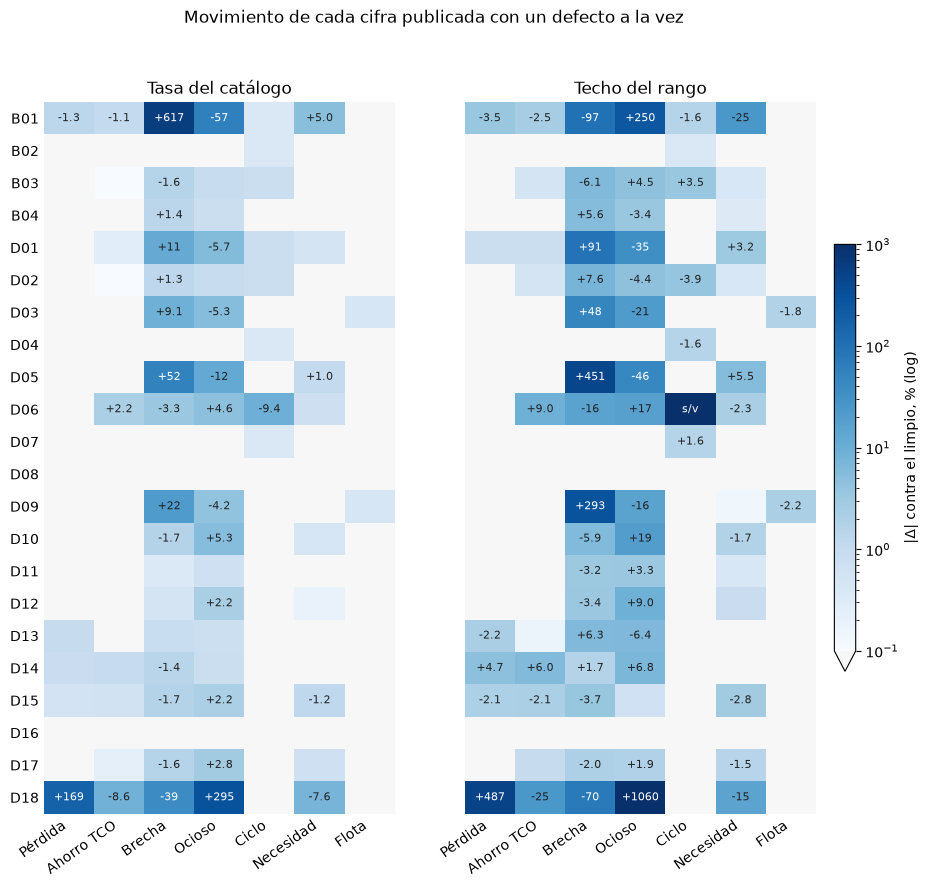

In [4]:
def matriz(nivel: str) -> tuple[np.ndarray, list[list[float | None]]]:
    m = np.zeros((len(defectos), len(CIFRAS)))
    signo = [[None] * len(CIFRAS) for _ in defectos]
    sub = impacto.filter((pl.col("tipo") == "cifra") & (pl.col("nivel") == nivel))
    for r in sub.iter_rows(named=True):
        i, j = defectos.index(r["defecto"]), CIFRAS.index(r["medida"])
        if r["delta_pct"] is None:
            m[i, j] = np.nan
        else:
            m[i, j] = abs(r["delta_pct"])
            signo[i][j] = r["delta_pct"]
    return m, signo


norma = LogNorm(vmin=0.1, vmax=1000)
mapa = plt.get_cmap("Blues").copy()
mapa.set_under("#f7f7f7")
mapa.set_bad("#08306b")

fig, axes = plt.subplots(1, 2, figsize=(12, 0.42 * len(defectos)), sharey=True)
for ax, nivel, titulo in zip(
    axes, ["tasa", "techo"], ["Tasa del catálogo", "Techo del rango"], strict=True
):
    m, signo = matriz(nivel)
    im = ax.imshow(np.where(m < 0.1, 0.01, m), cmap=mapa, norm=norma, aspect="auto")
    for i in range(len(defectos)):
        for j in range(len(CIFRAS)):
            v = m[i, j]
            if np.isnan(v):
                ax.text(j, i, "s/v", ha="center", va="center", fontsize=8, color="white")
            elif v > materialidad:
                d = signo[i][j]
                txt = f"{d:+.0f}" if abs(d) >= 10 else f"{d:+.1f}"
                ax.text(
                    j,
                    i,
                    txt,
                    ha="center",
                    va="center",
                    fontsize=8,
                    color="white" if v > 30 else TINTA,
                )
    ax.set_xticks(range(len(CIFRAS)), [NOMBRE[c] for c in CIFRAS], rotation=35, ha="right")
    ax.set_yticks(range(len(defectos)), defectos)
    ax.set_title(titulo)
    ax.spines[["left", "bottom"]].set_visible(False)
    ax.tick_params(length=0)
cb = fig.colorbar(im, ax=axes, shrink=0.6, pad=0.02, extend="min")
cb.set_label("|Δ| contra el limpio, % (log)")
fig.suptitle("Movimiento de cada cifra publicada con un defecto a la vez", x=0.45)
fig.savefig(IMG / "impacto_defectos.png", dpi=150, bbox_inches="tight")
plt.show()

In [5]:
cifras = impacto.filter(pl.col("tipo") == "cifra")


def mueve(defecto: str, nivel: str, cifra: str) -> float | None:
    return cifras.filter(
        (pl.col("defecto") == defecto) & (pl.col("nivel") == nivel) & (pl.col("medida") == cifra)
    )["delta_pct"].item()


materiales = cifras.filter(pl.col("supera_materialidad"))
por_cifra = materiales.group_by("medida").agg(pl.col("defecto").n_unique().alias("n"))
n_cifra = dict(por_cifra.iter_rows())
sin_nada = sorted(
    set(defectos)
    - set(materiales["defecto"])
    - set(impacto.filter((pl.col("tipo") == "identidad") & (pl.col("valor") > 0))["defecto"])
)
_lineas = [
    f"- D18, el precio de una planta en moneda local leído como USD, mueve la pérdida "
    f"{pct(mueve('D18', 'tasa', 'perdida'))} y el capital ocioso "
    f"{pct(mueve('D18', 'tasa', 'ocioso'))} a la tasa del catálogo. Antes de Fase 4 no "
    "tronaba ningún test.",
    f"- D05, el signo invertido a la tasa del catálogo, mueve la brecha "
    f"{pct(mueve('D05', 'tasa', 'brecha'))}; en el techo, {pct(mueve('D05', 'techo', 'brecha'))}.",
    f"- D06, la cantidad capturada en piezas, mueve el ciclo {pct(mueve('D06', 'tasa', 'ciclo'))}; "
    "en el techo deja sin cohortes completas y el ciclo de Fase 1 desaparece.",
    f"- El capital ocioso es la cifra que más defectos mueven: {n_cifra.get('ocioso', 0)} de "
    f"{len(defectos)}. Sale del mismo balance que la brecha, y cualquier cosa que cambie la "
    "flota o la necesidad lo mueve.",
    f"- No mueven ninguna cifra ni rompen una identidad: {', '.join(sin_nada)}.",
]
display(Markdown("\n".join(_lineas)))

- D18, el precio de una planta en moneda local leído como USD, mueve la pérdida +169.3% y el capital ocioso +294.9% a la tasa del catálogo. Antes de Fase 4 no tronaba ningún test.
- D05, el signo invertido a la tasa del catálogo, mueve la brecha +52.4%; en el techo, +451.2%.
- D06, la cantidad capturada en piezas, mueve el ciclo -9.4%; en el techo deja sin cohortes completas y el ciclo de Fase 1 desaparece.
- El capital ocioso es la cifra que más defectos mueven: 17 de 22. Sale del mismo balance que la brecha, y cualquier cosa que cambie la flota o la necesidad lo mueve.
- No mueven ninguna cifra ni rompen una identidad: D08, D16.

## 3. El valor expuesto no predice cuánto se mueve una cifra

`usd_expuesto` se calcula sobre un extracto real, sin corrida limpia de
contraste: es el valor a costo del maestro de lo que toca la regla. El delta solo
lo da el arnés. Si el primero predijera al segundo, el arnés sobraría.

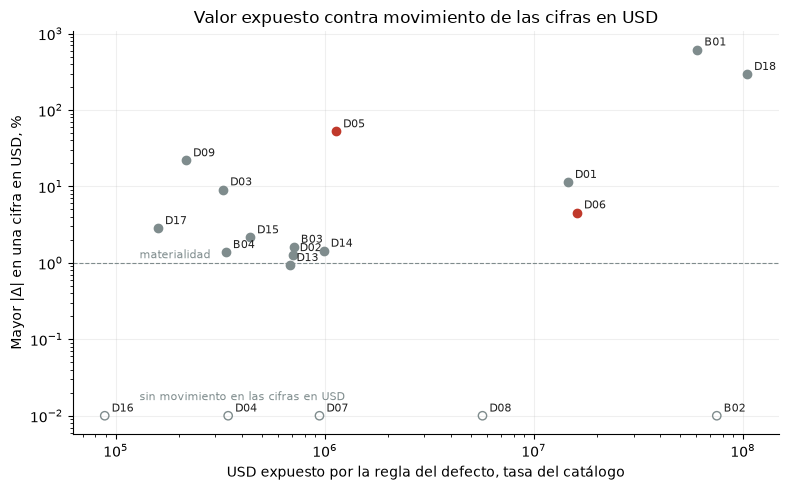

In [6]:
expuesto = impacto.filter(
    (pl.col("tipo") == "regla")
    & (pl.col("nivel") == "tasa")
    & (pl.col("medida") == pl.col("regla"))
).select("defecto", "usd_expuesto")
maximo = (
    cifras.filter((pl.col("nivel") == "tasa") & pl.col("medida").is_in(USD))
    .group_by("defecto")
    .agg(pl.col("delta_pct").abs().max().alias("delta"))
)
puntos = expuesto.join(maximo, on="defecto").filter(pl.col("usd_expuesto").is_not_null())
piso = 0.01

fig, ax = plt.subplots(figsize=(8, 5))
for r in puntos.iter_rows(named=True):
    y = max(r["delta"], piso)
    destaca = r["defecto"] in ("D05", "D06")
    ax.scatter(
        r["usd_expuesto"],
        y,
        s=36,
        color=ROJO if destaca else GRIS,
        facecolors="none" if r["delta"] < piso else None,
        zorder=3,
    )
    ax.annotate(
        r["defecto"],
        (r["usd_expuesto"], y),
        xytext=(5, 3),
        textcoords="offset points",
        fontsize=8,
        color=TINTA,
    )
ax.axhline(materialidad, color=GRIS, linestyle="--", linewidth=0.8)
ax.text(1.3e5, materialidad * 1.15, "materialidad", fontsize=8, color=GRIS)
ax.text(1.3e5, piso * 1.6, "sin movimiento en las cifras en USD", fontsize=8, color=GRIS)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("USD expuesto por la regla del defecto, tasa del catálogo")
ax.set_ylabel("Mayor |Δ| en una cifra en USD, %")
ax.set_title("Valor expuesto contra movimiento de las cifras en USD")
ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(IMG / "expuesto_vs_delta.png", dpi=150)
plt.show()

In [7]:
_r = (
    puntos.with_columns(
        pl.col("usd_expuesto").rank().alias("rx"), pl.col("delta").rank().alias("ry")
    )
    .select(pl.corr("rx", "ry"))
    .item()
)
d5 = puntos.filter(pl.col("defecto") == "D05").row(0, named=True)
d6 = puntos.filter(pl.col("defecto") == "D06").row(0, named=True)
_lineas = [
    f"- D06 expone {usd(d6['usd_expuesto'])} y su mayor movimiento en USD es "
    f"{d6['delta']:.1f}%. D05 expone {usd(d5['usd_expuesto'])} y mueve la brecha "
    f"{d5['delta']:.1f}%.",
    f"- Correlación de rangos entre los dos, en los {puntos.height} defectos con valor "
    f"expuesto: {_r:.2f}. El valor expuesto ordena qué revisar primero; cuánto pesa en "
    "una cifra lo dice el arnés.",
    "- Los defectos del plan (D10, D11 y D12) no tienen valor expuesto: reportan piezas, "
    "no contenedores.",
]
display(Markdown("\n".join(_lineas)))

- D06 expone \$16.1M y su mayor movimiento en USD es 4.6%. D05 expone \$1.1M y mueve la brecha 52.4%.
- Correlación de rangos entre los dos, en los 19 defectos con valor expuesto: 0.22. El valor expuesto ordena qué revisar primero; cuánto pesa en una cifra lo dice el arnés.
- Los defectos del plan (D10, D11 y D12) no tienen valor expuesto: reportan piezas, no contenedores.

## 4. Severidad: el seed contra la medición

Un defecto bloquea si en alguno de los dos niveles rompe una identidad (llave,
stock, saldo en cliente o conservación de flota) o mueve una de las siete cifras
más que la materialidad; alerta en lo demás (ADR-028, punto 10; ADR-031, punto 6).
`assert_severidad_medida` compara el seed con esta medición en cada build.

In [8]:
IDENTIDAD = {"llave": "llave", "stock": "stock", "saldo": "saldo", "conservacion": "conservación"}
identidad = impacto.filter((pl.col("tipo") == "identidad") & (pl.col("valor") > 0))
rotas = {
    d: [IDENTIDAD[k] for k in IDENTIDAD if k in set(g["medida"])]
    for (d,), g in identidad.group_by("defecto")
}


def mayor(nivel: str) -> dict[str, float]:
    sub = cifras.filter(pl.col("nivel") == nivel)
    out = {}
    for d in defectos:
        s = sub.filter(pl.col("defecto") == d)
        out[d] = float("inf") if s["delta_pct"].null_count() else s["delta_pct"].abs().max()
    return out


m_tasa, m_techo = mayor("tasa"), mayor("techo")
con_defecto = reglas.filter(pl.col("defecto").is_not_null())
severidad = dict(con_defecto.select("defecto", "severidad").iter_rows())


def decide(d: str) -> str:
    if d in rotas:
        return "identidad"
    if m_tasa[d] > materialidad:
        return "tasa"
    if m_techo[d] > materialidad:
        return "solo el techo"
    return "nada"


_filas = [
    "| Defecto | Seed | Identidad rota | Mayor \\|Δ\\| a tasa | En el techo | Lo decide |",
    "|---|---|---|---:|---:|---|",
]
for d in defectos:
    f = lambda v: "sin valor" if v == float("inf") else f"{v:.1f}%"  # noqa: E731
    _filas.append(
        f"| {d} | {severidad[d]} | {', '.join(rotas.get(d, [])) or '—'} | {f(m_tasa[d])} | "
        f"{f(m_techo[d])} | {decide(d)} |"
    )
display(Markdown("\n".join(_filas)))

| Defecto | Seed | Identidad rota | Mayor \|Δ\| a tasa | En el techo | Lo decide |
|---|---|---|---:|---:|---|
| B01 | bloquea | stock, saldo | 616.8% | 250.0% | identidad |
| B02 | bloquea | saldo | 0.4% | 0.4% | identidad |
| B03 | bloquea | stock | 1.6% | 6.1% | identidad |
| B04 | bloquea | saldo | 1.4% | 5.6% | identidad |
| D01 | bloquea | llave, stock, saldo | 11.4% | 90.8% | identidad |
| D02 | bloquea | stock, saldo | 1.3% | 7.6% | identidad |
| D03 | bloquea | stock, conservación | 9.1% | 47.9% | identidad |
| D04 | bloquea | saldo | 0.4% | 1.6% | identidad |
| D05 | bloquea | stock, conservación | 52.4% | 451.2% | identidad |
| D06 | bloquea | stock | 9.4% | sin valor | identidad |
| D07 | bloquea | saldo | 0.4% | 1.6% | identidad |
| D08 | alerta | — | 0.0% | 0.0% | nada |
| D09 | bloquea | stock | 21.9% | 293.4% | identidad |
| D10 | bloquea | — | 5.3% | 19.4% | tasa |
| D11 | bloquea | — | 0.7% | 3.3% | solo el techo |
| D12 | bloquea | — | 2.2% | 9.0% | tasa |
| D13 | bloquea | — | 0.9% | 6.4% | solo el techo |
| D14 | bloquea | — | 1.4% | 6.8% | tasa |
| D15 | bloquea | — | 2.2% | 3.7% | tasa |
| D16 | alerta | — | 0.0% | 0.0% | nada |
| D17 | bloquea | — | 2.8% | 2.0% | tasa |
| D18 | bloquea | — | 294.9% | 1060.4% | tasa |

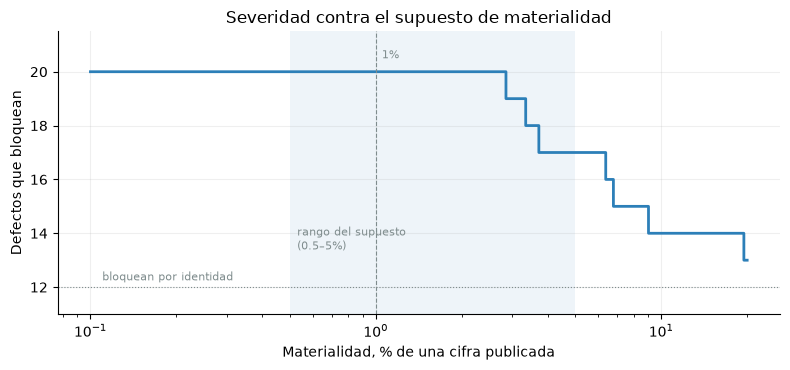

In [9]:
def bloquean(m: float) -> int:
    return sum(1 for d in defectos if d in rotas or max(m_tasa[d], m_techo[d]) > m)


rejilla = np.logspace(np.log10(0.1), np.log10(20), 600)
conteo = [bloquean(m) for m in rejilla]

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.axvspan(0.5, 5, color=AZUL, alpha=0.08, lw=0)
ax.step(rejilla, conteo, where="post", color=AZUL, linewidth=2)
ax.axvline(materialidad, color=GRIS, linestyle="--", linewidth=0.8)
por_identidad = sum(1 for d in defectos if d in rotas)
ax.axhline(por_identidad, color=GRIS, linestyle=":", linewidth=0.8)
ax.text(0.11, por_identidad + 0.25, "bloquean por identidad", fontsize=8, color=GRIS)
ax.text(materialidad * 1.05, max(conteo) + 0.5, f"{materialidad:g}%", fontsize=8, color=GRIS)
ax.text(0.53, por_identidad + 1.4, "rango del supuesto\n(0.5–5%)", fontsize=8, color=GRIS)
ax.set_xscale("log")
ax.set_ylim(por_identidad - 1, max(conteo) + 1.5)
ax.set_xlabel("Materialidad, % de una cifra publicada")
ax.set_ylabel("Defectos que bloquean")
ax.set_title("Severidad contra el supuesto de materialidad")
ax.grid(alpha=0.2)
fig.tight_layout()
fig.savefig(IMG / "sensibilidad_materialidad.png", dpi=150)
plt.show()

In [10]:
sin_identidad = [d for d in defectos if d not in rotas]
cortes = sorted(
    (max(m_tasa[d], m_techo[d]), d) for d in sin_identidad if max(m_tasa[d], m_techo[d]) > 0
)
estable = min(v for v, _ in cortes if v > materialidad)
a_5 = [d for v, d in cortes if materialidad < v <= 5]
coincide = sum(
    1 for d in defectos if severidad[d] == ("bloquea" if decide(d) != "nada" else "alerta")
)
_lineas = [
    f"- El seed coincide con la medición en {coincide} de {len(defectos)} defectos.",
    f"- {sum(1 for d in defectos if d in rotas)} defectos bloquean por romper una identidad, "
    "sin importar la materialidad.",
    f"- Solo el techo los hace bloquear: "
    f"{', '.join(d for d in defectos if decide(d) == 'solo el techo')}. A la tasa del catálogo "
    "no llegan a la materialidad.",
    f"- La severidad no cambia mientras la materialidad quede debajo de {estable:.2f}%. Con 5%, "
    f"{', '.join(sorted(a_5))} pasarían a alerta.",
]
display(Markdown("\n".join(_lineas)))

- El seed coincide con la medición en 22 de 22 defectos.
- 12 defectos bloquean por romper una identidad, sin importar la materialidad.
- Solo el techo los hace bloquear: D11, D13. A la tasa del catálogo no llegan a la materialidad.
- La severidad no cambia mientras la materialidad quede debajo de 2.84%. Con 5%, D11, D15, D17 pasarían a alerta.

El techo no siempre es el peor caso: hay defectos que mueven más a la tasa del
catálogo que en el techo, porque la brecha pasa por compras en contenedores
enteros, préstamos y la z. Por eso la severidad se decide con los dos niveles.

## 5. Tablero sobre la base abierta

`mart_calidad_datos` cuenta las violaciones por regla, planta y material del
extracto que se cargó. Sobre el dataset limpio no hay ninguna. Para verlo con
los defectos encendidos, el dashboard abre la base que indique `RPI_DB` (README,
sección de calidad).

In [11]:
tablero = q("""
    SELECT r.regla, r.defecto, r.unidad, r.severidad, r.cifra_afectada,
           COALESCE(SUM(m.violaciones), 0)::BIGINT   AS violaciones,
           SUM(m.usd_expuesto)                       AS usd_expuesto
    FROM reglas_calidad r
    LEFT JOIN mart_calidad_datos m USING (regla)
    GROUP BY ALL
    ORDER BY r.severidad, violaciones DESC, r.regla
""")
total = tablero["violaciones"].sum()
_filas = [
    "| Regla | Defecto | Severidad | Cifras afectadas | Violaciones |",
    "|---|---|---|---|---:|",
]
for r in tablero.iter_rows(named=True):
    _filas.append(
        f"| `{r['regla']}` | {r['defecto'] or '—'} | {r['severidad']} | "
        f"{r['cifra_afectada'] or 'ninguna'} | {r['violaciones']:,} |"
    )
_cabeza = (
    f"{total:,} violaciones en {tablero.height} reglas sobre la base abierta."
    if total
    else f"Sin violaciones en las {tablero.height} reglas: la base abierta es el limpio."
)
display(Markdown(_cabeza + "\n\n" + "\n".join(_filas)))

Sin violaciones en las 27 reglas: la base abierta es el limpio.

| Regla | Defecto | Severidad | Cifras afectadas | Violaciones |
|---|---|---|---|---:|
| `precio_documento_distinto` | D16 | alerta | ninguna | 0 |
| `registro_despues_del_cierre` | D08 | alerta | serie_mensual | 0 |
| `budat_despues_del_corte` | B04 | bloquea | brecha ocioso necesidad saldo_cliente | 0 |
| `bwart_fuera_de_catalogo` | D02 | bloquea | brecha ocioso ciclo flota saldo_cliente | 0 |
| `cantidad_en_piezas` | D06 | bloquea | tco brecha ocioso ciclo necesidad | 0 |
| `cliente_vacio` | D04 | bloquea | ciclo saldo_cliente | 0 |
| `documento_repetido` | B03 | bloquea | tco brecha ocioso ciclo necesidad | 0 |
| `error_de_schema` | — | bloquea | todas | 0 |
| `grupo_contradice_codigo` | D14 | bloquea | perdida tco brecha ocioso | 0 |
| `grupo_fuera_de_catalogo` | D17 | bloquea | todas | 0 |
| `instruccion_a_desechable` | D12 | bloquea | brecha ocioso necesidad | 0 |
| `instruccion_fuera_de_planta` | — | bloquea | brecha ocioso necesidad | 0 |
| `kunnr_con_formato` | B02 | bloquea | ciclo saldo_cliente | 0 |
| `lgort_fuera_de_catalogo` | D03 | bloquea | brecha ocioso flota | 0 |
| `llave_duplicada` | D01 | bloquea | todas | 0 |
| `llave_maestro_duplicada` | — | bloquea | todas | 0 |
| `llave_plan_duplicada` | — | bloquea | brecha ocioso necesidad | 0 |
| `material_sin_foto` | D09 | bloquea | brecha ocioso flota | 0 |
| `material_sin_maestro` | D15 | bloquea | todas | 0 |
| `matnr_con_formato` | B01 | bloquea | todas | 0 |
| `moneda_distinta` | D18 | bloquea | perdida tco brecha ocioso necesidad | 0 |
| `parte_sin_instruccion` | D10 | bloquea | brecha ocioso necesidad | 0 |
| `parte_sin_registro` | — | bloquea | brecha ocioso necesidad | 0 |
| `piezas_en_cero` | D11 | bloquea | brecha ocioso necesidad | 0 |
| `recogida_sin_saldo` | D07 | bloquea | ciclo saldo_cliente | 0 |
| `signo_invertido` | D05 | bloquea | brecha ocioso necesidad flota | 0 |
| `unidad_de_precio` | D13 | bloquea | perdida brecha ocioso | 0 |

## 6. Defectos ciegos: antes y después de su regla

Las reglas de Fase 4 se escribieron conociendo los 18 defectos, así que su 100%
no dice qué pasa con un defecto que nadie anticipó. Los cuatro ciegos (ADR-033)
se inyectaron y se midieron en el completo antes de escribir sus reglas; esa
medición quedó en `docs/calidad/ciegos_antes.csv`, en un commit anterior al de
las reglas. Después entraron las cuatro reglas y la fecha de extracción como var
(ADR-034), y el arnés los midió otra vez con la misma inyección.

In [12]:
ciegos = q("SELECT * FROM mart_deteccion_ciegos ORDER BY defecto, nivel")


def mueve_ciego(cifra: str, delta: float) -> str:
    return f"{NOMBRE[cifra]} {delta:+.1f}%"


def reglas_md(texto: str) -> str:
    partes = (p.rsplit(" ", 1) for p in texto.split(", "))
    return ", ".join(f"`{regla}` {int(n):,}" for regla, n in partes)


_filas = [
    "| Ciego | Regla | Nivel | Casos | Antes | Después | Más movía antes | Más mueve después |",
    "|---|---|---|---:|---:|---:|---|---|",
]
for r in ciegos.iter_rows(named=True):
    antes = "sin regla" if r["detectados_antes"] is None else f"{r['detectados_antes']:,}"
    _filas.append(
        f"| {r['defecto']} | `{r['regla']}` | {r['nivel']} | {r['casos']:,} | {antes} | "
        f"{r['pct_detectados_despues']:.0f}% | "
        f"{mueve_ciego(r['cifra_antes'], r['delta_pct_antes'])} | "
        f"{mueve_ciego(r['cifra_despues'], r['delta_pct_despues'])} |"
    )
display(Markdown("\n".join(_filas)))

| Ciego | Regla | Nivel | Casos | Antes | Después | Más movía antes | Más mueve después |
|---|---|---|---:|---:|---:|---|---|
| B01 | `matnr_con_formato` | tasa | 209,117 | sin regla | 100% | Brecha +616.8% | Brecha +616.8% |
| B01 | `matnr_con_formato` | techo | 510,453 | sin regla | 100% | Ocioso +250.0% | Ocioso +250.0% |
| B02 | `kunnr_con_formato` | tasa | 293,408 | sin regla | 100% | Ciclo -0.4% | Ciclo -0.4% |
| B02 | `kunnr_con_formato` | techo | 647,246 | sin regla | 100% | Ciclo -0.4% | Ciclo -0.4% |
| B03 | `documento_repetido` | tasa | 3,968 | sin regla | 100% | Brecha -1.6% | Brecha -1.6% |
| B03 | `documento_repetido` | techo | 19,846 | sin regla | 100% | Brecha -6.1% | Brecha -6.1% |
| B04 | `budat_despues_del_corte` | tasa | 1,987 | sin regla | 100% | Brecha +31.0% | Brecha +1.4% |
| B04 | `budat_despues_del_corte` | techo | 7,940 | sin regla | 100% | Brecha +31.0% | Brecha +5.6% |

In [13]:
tasa_c = ciegos.filter(pl.col("nivel") == "tasa")
vistos = tasa_c.filter(pl.col("otras_reglas_antes").is_not_null())
completos_c = ciegos.filter(pl.col("pct_detectados_despues") == 100)["defecto"].n_unique()
b04 = {r["nivel"]: r for r in ciegos.filter(pl.col("defecto") == "B04").iter_rows(named=True)}
_lineas = [
    f"- Antes de su regla, ninguno llegaba con su causa. {vistos.height} de {tasa_c.height} "
    "los veía una regla de otro defecto:",
]
for r in vistos.iter_rows(named=True):
    _lineas.append(f"  - {r['defecto']}: {reglas_md(r['otras_reglas_antes'])}.")
_lineas += [
    f"- Después, la regla de cada uno reporta el 100% en los dos niveles: {completos_c} de "
    f"{tasa_c.height}.",
    f"- B04 movía la brecha {b04['tasa']['delta_pct_antes']:+.1f}% igual a tasa que en el "
    "techo: los modelos tomaban el corte de max(Budat) y una sola línea con fecha posterior "
    "corría todo el calendario. Con la fecha de extracción como var, "
    f"{b04['tasa']['delta_pct_despues']:+.1f}% a tasa y "
    f"{b04['techo']['delta_pct_despues']:+.1f}% en el techo.",
]
otras_d = ciegos.filter(pl.col("otras_reglas_despues").is_not_null())
for r in otras_d.iter_rows(named=True):
    _lineas.append(
        f"- {r['defecto']} en {r['nivel']} todavía dispara {reglas_md(r['otras_reglas_despues'])}: "
        "recogidas de cuentas cuya salida quedó después del corte, un síntoma aguas abajo."
    )
display(Markdown("\n".join(_lineas)))

- Antes de su regla, ninguno llegaba con su causa. 3 de 4 los veía una regla de otro defecto:
  - B01: `material_sin_maestro` 140, `recogida_sin_saldo` 3,100.
  - B02: `recogida_sin_saldo` 293,408.
  - B04: `recogida_sin_saldo` 5.
- Después, la regla de cada uno reporta el 100% en los dos niveles: 4 de 4.
- B04 movía la brecha +31.0% igual a tasa que en el techo: los modelos tomaban el corte de max(Budat) y una sola línea con fecha posterior corría todo el calendario. Con la fecha de extracción como var, +1.4% a tasa y +5.6% en el techo.
- B04 en tasa todavía dispara `recogida_sin_saldo` 5: recogidas de cuentas cuya salida quedó después del corte, un síntoma aguas abajo.
- B04 en techo todavía dispara `recogida_sin_saldo` 28: recogidas de cuentas cuya salida quedó después del corte, un síntoma aguas abajo.

## 7. Resumen ejecutivo

In [14]:
def mas_mueve(d: str, nivel: str) -> str:
    s = cifras.filter((pl.col("defecto") == d) & (pl.col("nivel") == nivel))
    if s["delta_pct"].null_count():
        c = s.filter(pl.col("delta_pct").is_null())["medida"][0]
        return f"{NOMBRE[c]} sin valor"
    r = s.sort(pl.col("delta_pct").abs(), descending=True).row(0, named=True)
    return "nada" if abs(r["delta_pct"]) < 0.05 else f"{NOMBRE[r['medida']]} {r['delta_pct']:+.1f}%"


_filas = [
    "| Defecto | Regla | Severidad | Identidad rota | Más mueve a tasa | En el techo |",
    "|---|---|---|---|---|---|",
]
regla = dict(con_defecto.select("defecto", "regla").iter_rows())
for d in defectos:
    _filas.append(
        f"| {d} | `{regla[d]}` | {severidad[d]} | {', '.join(rotas.get(d, [])) or '—'} | "
        f"{mas_mueve(d, 'tasa')} | {mas_mueve(d, 'techo')} |"
    )
display(Markdown("\n".join(_filas)))

| Defecto | Regla | Severidad | Identidad rota | Más mueve a tasa | En el techo |
|---|---|---|---|---|---|
| B01 | `matnr_con_formato` | bloquea | stock, saldo | Brecha +616.8% | Ocioso +250.0% |
| B02 | `kunnr_con_formato` | bloquea | saldo | Ciclo -0.4% | Ciclo -0.4% |
| B03 | `documento_repetido` | bloquea | stock | Brecha -1.6% | Brecha -6.1% |
| B04 | `budat_despues_del_corte` | bloquea | saldo | Brecha +1.4% | Brecha +5.6% |
| D01 | `llave_duplicada` | bloquea | llave, stock, saldo | Brecha +11.4% | Brecha +90.8% |
| D02 | `bwart_fuera_de_catalogo` | bloquea | stock, saldo | Brecha +1.3% | Brecha +7.6% |
| D03 | `lgort_fuera_de_catalogo` | bloquea | stock, conservación | Brecha +9.1% | Brecha +47.9% |
| D04 | `cliente_vacio` | bloquea | saldo | Ciclo -0.4% | Ciclo -1.6% |
| D05 | `signo_invertido` | bloquea | stock, conservación | Brecha +52.4% | Brecha +451.2% |
| D06 | `cantidad_en_piezas` | bloquea | stock | Ciclo -9.4% | Ciclo sin valor |
| D07 | `recogida_sin_saldo` | bloquea | saldo | Ciclo +0.4% | Ciclo +1.6% |
| D08 | `registro_despues_del_cierre` | alerta | — | nada | nada |
| D09 | `material_sin_foto` | bloquea | stock | Brecha +21.9% | Brecha +293.4% |
| D10 | `parte_sin_instruccion` | bloquea | — | Ocioso +5.3% | Ocioso +19.4% |
| D11 | `piezas_en_cero` | bloquea | — | Ocioso +0.7% | Ocioso +3.3% |
| D12 | `instruccion_a_desechable` | bloquea | — | Ocioso +2.2% | Ocioso +9.0% |
| D13 | `unidad_de_precio` | bloquea | — | Pérdida -0.9% | Ocioso -6.4% |
| D14 | `grupo_contradice_codigo` | bloquea | — | Brecha -1.4% | Ocioso +6.8% |
| D15 | `material_sin_maestro` | bloquea | — | Ocioso +2.2% | Brecha -3.7% |
| D16 | `precio_documento_distinto` | alerta | — | nada | nada |
| D17 | `grupo_fuera_de_catalogo` | bloquea | — | Ocioso +2.8% | Brecha -2.0% |
| D18 | `moneda_distinta` | bloquea | — | Ocioso +294.9% | Ocioso +1060.4% |

In [15]:
con.close()